# hiNiche: human colorectal cancer Visium HD analysis

Multi-scale (spot / cell / niche) cell-type deconvolution and niche discovery on Visium HD colorectal cancer (CRC) data.

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`). Inputs: the nucleus segmentation mask from step 1 (`segmentation_mask.npz`) and the reference profiles from step 2 (`lambda_matrix.csv`).

## 1. Setup and imports

In [65]:
import os
import sys
# cupy (used by rapids_singlecell) compiles GPU kernels at runtime and needs the CUDA headers shipped inside the conda environment
os.environ.setdefault("CUDA_PATH", os.path.join(sys.prefix, "targets", "x86_64-linux"))

# --- Project modules ---
import config
import utils
from train import run_train_seq

# --- Standard library ---
import json
import warnings

# --- Data handling ---
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import scipy.sparse as sp
import pyarrow.parquet as pq

# --- Deep learning ---
import torch
import torch.nn.functional as F

# --- Clustering ---
import rapids_singlecell as rsc     # GPU-accelerated neighbors / Leiden / UMAP
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

# --- Plotting ---
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Parameter configuration

In [69]:
SAMPLE = "CRC_HD_single_slice"

# Data paths
h5_path              = f"DATA/{SAMPLE}/filtered_feature_bc_matrix.h5"
possition_path       = f"DATA/{SAMPLE}/tissue_positions.parquet"
refile_path          = f"DATA/{SAMPLE}/lambda_matrix.csv"
cell_seg_labels_path = f"DATA/{SAMPLE}/segmentation_mask.npz"

#Patch save path
PATCH_LOC = f"DATA/{SAMPLE}/mini_batch_cache"

#Model save path
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Cell-type color map defined in config.py
celltype_color = getattr(config, "colormap_coloncatlas_18")
umap_color = getattr(config, "umap_40")
# Model / training hyperparameters
Patch_size  = 512
graph_knn   = 12
niche_knn   = 15
lr          = 0.005
num_epochs  = 30
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
alpha       = 1
beta        = 1
seed        = 42
device      = "cuda:0"

## 3. Data loading and preprocessing

### 3.1 Load counts and spot positions

In [3]:
# Reference expression profiles (genes x cell types) and nucleus segmentation labels
ref_df = pd.read_csv(refile_path, index_col = 0)
cell_seg_labels = sp.load_npz(cell_seg_labels_path)

# Load counts
adata = sc.read_10x_h5(h5_path)

# Load spot positions
positions = pq.read_table(possition_path).to_pandas()
positions = positions.set_index("barcode")

# Merge positions into obs
adata.obs = adata.obs.join(positions)

# Keep only in-tissue spots (in_tissue == 1)
adata = adata[adata.obs["in_tissue"].fillna(0).astype(int) == 1].copy()

# Grid (array row/col) and full-resolution pixel coordinates
adata.obsm["spatial_grid"]  = adata.obs[["array_row", "array_col"]].to_numpy()
adata.obsm["spatial_pixel"] = adata.obs[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values

### 3.2 Quality control, background filtering, and normalization

In [4]:
# Keep raw counts before normalization
adata.layers["counts"] = adata.X.copy()

adata.var_names_make_unique()

# Flag low-count background regions and drop them
adata = utils.background_detector(adata, threshold = 50, n_neighs =4, n_rings = 4)
print(f"[Log] original adata size is {adata.shape}")

before = adata.shape[0]
adata = adata[adata.obs["low_count_region"] < 1]
after = adata.shape[0]
print(f"[Log] filtering background: {before} spots to {after} spots")

# Library-size normalization + log transform
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

[Log] original adata size is (8731400, 18085)
[Log] filtering background: 8731400 spots to 7432511 spots


### 3.3 Align genes with the reference

In [5]:
# Restrict to genes shared between the data and the reference
overlap_gs = adata.var.index.intersection(ref_df.index)
print(f"[Log] num of gene overlap {len( overlap_gs )}")

adata.obsm["X_mle"] = adata.layers["counts"][:, adata.var_names.isin(overlap_gs)]   # raw counts
adata.obsm["X_input"] = adata[:, adata.var_names.isin(overlap_gs)].X                # normalized model input

print(f"[Log] input gene number is {len(overlap_gs)}")
ref_matrix = ref_df.loc[overlap_gs].values
ref_matrix = np.array(ref_matrix)

celltypes = list(ref_df.columns)
print(f"[Log] rna ref size is {ref_matrix.shape}")

[Log] num of gene overlap 6008
[Log] input gene number is 6008
[Log] rna ref size is (6008, 18)


## 4. Build the spot / cell / niche hierarchy

### 4.1 Spot-to-cell and spot-to-niche assignment

In [6]:
# Spot -> cell assignment from nucleus segmentation
S_s2c_all, cell_background_mask = utils.spot2cell_nuclieseg(adata.obsm["spatial_pixel"], cell_seg_labels, max_spots_per_cell=100, min_spots_per_cell= 3)
print(f"[Log] {S_s2c_all.shape[1]} cells are detected")

# Spot -> niche assignment: each niche is a cell plus its nearest neighbors
S_s2n_all, niche_background_mask, active_niche_indices, S_c2n_all = utils.spot2niche_by_cell_knn(adata.obsm["spatial_grid"], S_s2c_all, k_niche=niche_knn)
background_mask = {"cell": cell_background_mask, "niche":niche_background_mask}

[Log] Active Cells (before filtering): 552203
[Log] Valid Cells (3 <= spots <= 100): 373439
[Log] Filtered Cells (< 3 spots): 178764
[Log] Filtered Cells (> 100 spots): 0
[Log] 373439 cells are detected
[Log] Active Niches: 373439, Cells per Niche (k): 15


### 4.2 Spatial KNN graphs

In [7]:
# Spatial KNN graphs at spot and cell level
spot_edges = utils.build_spot_knn_graph(adata.obsm["spatial_grid"], graph_knn)
cell_edges = utils.build_cell_knn_graph(adata.obsm["spatial_grid"], S_s2c_all, graph_knn)
# Niche graph: reuses the cell KNN graph (one niche per cell), same k as spot/cell graphs
niche_edges = cell_edges

[Log] 90083410 edges generated from 7432511 nodes (k=12)
[Log] 5072262 edges generated from 373439 nodes (k=12)


### 4.3 Spatial blocking and subgraph caching

In [8]:
# Split the slide into overlapping spatial blocks (core + halo) for mini-batch training
batch_mask, block_ids = utils.make_block_masks(adata.obsm["spatial_grid"], Patch_size=Patch_size, halo=32, S_s2c=S_s2c_all, S_s2n=S_s2n_all)

# Build and cache per-block subgraph data to disk
utils.build_subgraph_data(adata, ref_matrix, spot_edges, cell_edges, niche_edges,
                          S_s2c_all, S_s2n_all, S_c2n_all, background_mask, batch_mask, block_ids, PATCH_LOC)
print(f"[Log] Original ST is patchfied to {len(block_ids)} blocks with avg {batch_mask['spot_level_core'].sum(dim=1).float().mean().item():.0f} spots, {batch_mask['cell_level_core'].sum(dim=1).float().mean().item():.0f} cells and {batch_mask['niche_level_core'].sum(dim=1).float().mean().item():.0f} niches per block")

[Log] Generating spot masks for 49 blocks...


[Log] Building & saving mini-batches: 100%|██████████| 49/49 [07:34<00:00,  9.28s/it]


[Log] Saved 41 blocks → DATA/CRC_HD_single_slice/mini_batch_cache
[Log] Original ST is patchfied to 49 blocks with avg 151684 spots, 7678 cells and 8090 niches per block


## 5. Model training

In [47]:
emb_all, slice_id = run_train_seq(total_unit_number_per_level = {"spot": S_s2c_all.shape[0], "cell": S_s2c_all.shape[1], "niche": S_s2n_all.shape[1]},
                                  PATCH_LOC = PATCH_LOC,
                                  MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                  ref_matrix = ref_matrix,
                                  lr = lr,
                                  in_dim = len(overlap_gs),
                                  hidden_dim = len(celltypes),
                                  num_epochs = num_epochs,
                                  edge_drop = edge_drop,
                                  member_drop = member_drop,
                                  neg_samples = neg_samples,
                                  tau = tau,
                                  alpha = alpha,
                                  beta = beta,
                                  seed = seed,
                                  device = device)

Epoch 30: 100%|██████████| 41/41 [00:12<00:00,  3.18it/s, cl=4.9408, nll=458.1254, entp=-3.1758]


Training finished!
Model saved to DATA/CRC_HD_single_slice/checkpoint.pt


generating embeddings (slice 0)...: 100%|██████████| 41/41 [00:11<00:00,  3.45it/s]


## 6. Re-assign unmapped spots

In [48]:
# Re-assign unmapped (background) spots to nearby cells using spot embeddings
spot_embs = emb_all["spot"].detach().cpu().numpy()
new_assignments = utils.reassign_unmapped_spots(
    S_s2c_all,
    adata.obsm["spatial_grid"],          # grid coordinates, 1 unit = 1 spot
    spot_embs,
    algorithm="fixed_boundary",
    fixed_distance=2,
)

print(f"[Log] {len(new_assignments)} background spots has been re-assigned")

S_s2c_updated = utils.update_S(S_s2c_all, new_assignments)

# Spots that were re-assigned are no longer background
cell_background_mask_updated = []
for i in range(len(cell_background_mask)):
    if i in new_assignments: cell_background_mask_updated.append(False)
    else: cell_background_mask_updated.append(bool(cell_background_mask[i]))

Total unassigned spots: 4876154


Assigning spots (boundary): 100%|██████████| 4876154/4876154 [02:47<00:00, 29080.93it/s]


[Log] 2911315 background spots has been re-assigned


## 7. Visualization

### 7.1 Spot- and cell-level cell-type maps

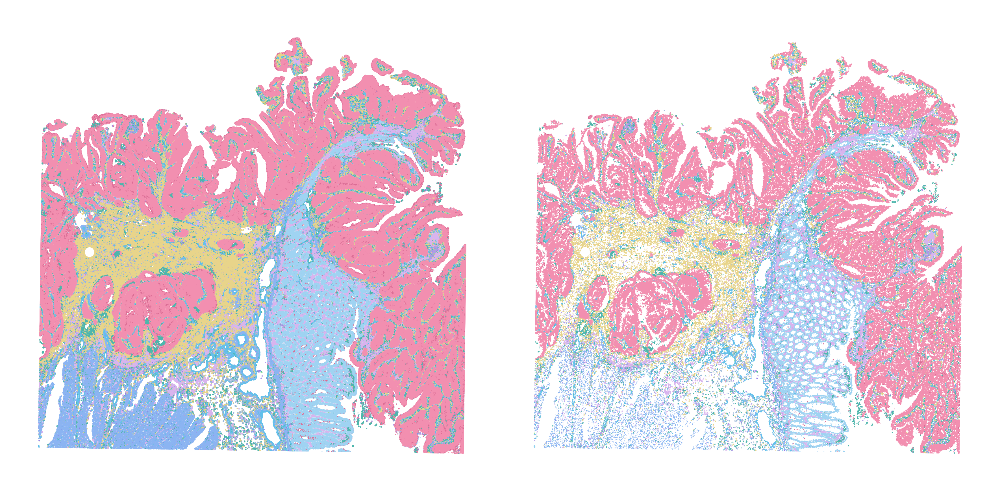

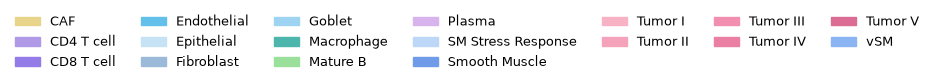

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(6, 3), dpi=600)   # left: spot level, right: cell level

keys = ["spot", "cell"]
labels_all = {}
for i, ax in enumerate(axes):
    check = keys[i]
    x_raw, y_raw = adata.obsm["spatial_pixel"][:, 0], adata.obsm["spatial_pixel"][:, 1]

    # Cell-type probabilities
    prob = F.softmax(emb_all[check], dim=1)
    max_prob_raw, max_idx_raw = torch.max(prob, dim=1)

    if check == "cell":
        # Broadcast each cell's prediction to its spots (spot -> cell mapping)
        S = S_s2c_updated.coalesce()
        rows, cols = S.indices()[0], S.indices()[1]
        spot2target = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
        spot2target[rows] = cols
        max_idx = torch.where(spot2target >= 0, max_idx_raw[spot2target], torch.tensor(-1, device=S.device))
        max_prob = torch.where(spot2target >= 0, max_prob_raw[spot2target], torch.tensor(0.0, device=S.device))
    else:
        max_prob, max_idx = max_prob_raw, max_idx_raw

    # --- Label assignment ---
    cell_labels = []
    for j in range(len(max_prob)):
        # max_idx == -1: the spot does not belong to any valid cell
        if max_idx[j] == -1:
            cell_labels.append("filtered")
        elif max_prob[j] < 0.1:
            cell_labels.append("ambiguous")
        else:
            cell_labels.append(celltypes[max_idx[j]])
    labels_all[check] = cell_labels

    colors = [celltype_color[name] for name in cell_labels]
    ax.scatter(x_raw, y_raw, c=colors, s=0.5, marker='.', linewidths=0)
    ax.invert_yaxis()
    ax.axis("off")

plt.tight_layout()
plt.show()

# --- Legend ---
cell_type = np.asarray(celltypes)[F.softmax(emb_all["spot"], dim=1).argmax(1).cpu().numpy()]
handles = [mpatches.Patch(color=celltype_color.get(c, "#cccccc"), label=c) for c in np.unique(cell_type)]
figL, axL = plt.subplots(figsize=(11, 0.6)); axL.axis("off")
axL.legend(handles=handles, ncol=7, frameon=False, loc="center", fontsize=9)
plt.show()

### 7.2 Niche clustering (UMAP + spatial map)

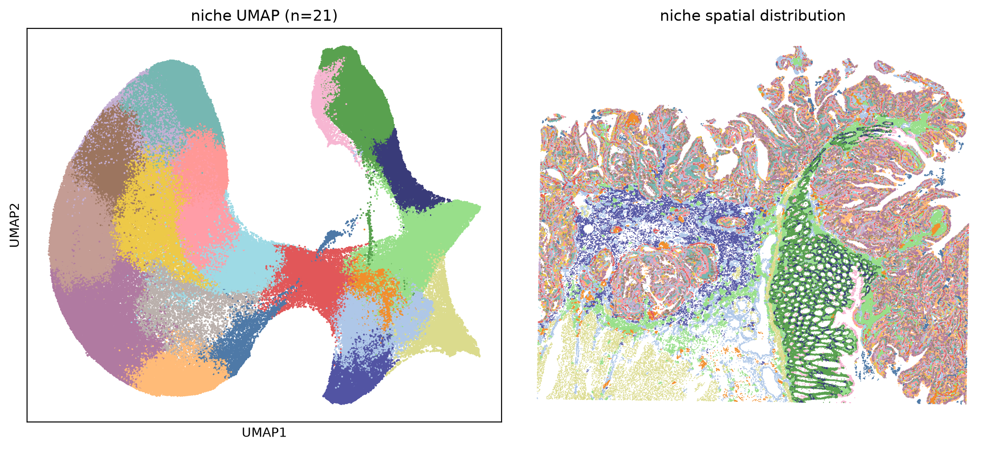

In [ ]:
import torch
torch.cuda.empty_cache()

resolution = 0.8   # Leiden resolution; higher -> more clusters
emb_k = 50

# --- 1. Cluster niche embeddings (Leiden) + UMAP, sharing one neighbor graph ---
adata_tmp = ad.AnnData(emb_all["niche"].numpy())
rsc.pp.neighbors(adata_tmp, use_rep='X', n_neighbors=emb_k)
rsc.tl.leiden(adata_tmp, resolution=resolution, random_state=seed)
rsc.tl.umap(adata_tmp, random_state=seed)
niche_label = adata_tmp.obs['leiden'].astype(int).values
niche_umap = adata_tmp.obsm["X_umap"]
clusters_id = {"niche": niche_label}
n_clusters = len(np.unique(niche_label))

# --- 2. Estimate each cell's position from S_s2c_updated (mean of its spots' coordinates) ---
S = S_s2c_updated.coalesce()
s_rows, c_cols = S.indices()
n_cell = S.size(1)
spatial = torch.as_tensor(adata.obsm["spatial_pixel"], dtype=torch.float32, device=S.device)

cell_pos = torch.zeros((n_cell, 2), device=S.device).index_add_(0, c_cols, spatial[s_rows])
cell_cnt = torch.zeros(n_cell, device=S.device).index_add_(0, c_cols, torch.ones_like(c_cols, dtype=torch.float32))
cell_pos /= cell_cnt.clamp(min=1).unsqueeze(1)

# --- 3. Map niche clusters back to cells ---
cell_niche = torch.full((n_cell,), -1, dtype=torch.long, device=S.device)
active = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche[active] = torch.as_tensor(niche_label, device=S.device).long()

keep = (cell_niche >= 0) & (cell_cnt > 0)
pos = cell_pos[keep].cpu().numpy()
ids = cell_niche[keep].cpu().numpy()

# --- 4. Left: niche UMAP; right: niche spatial distribution at cell level (umap_40 colors) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=200)

axes[0].scatter(niche_umap[:, 0], niche_umap[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in niche_label], s=2, linewidths=0)
axes[0].set_title(f"niche UMAP (n={n_clusters})")
axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_xlabel("UMAP1"); axes[0].set_ylabel("UMAP2")

axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v}"] for v in ids], s=2, marker='.', linewidths=0)
axes[1].set_title("niche spatial distribution")
axes[1].invert_yaxis(); axes[1].axis("off")

plt.tight_layout()
plt.show()

### 7.3 Merge niches by cell-type composition

21 niche clusters -> 10 merged
  [2, 16] -> 2
  [3, 4, 5, 6, 7, 8, 9, 11, 13, 15, 18] -> 3


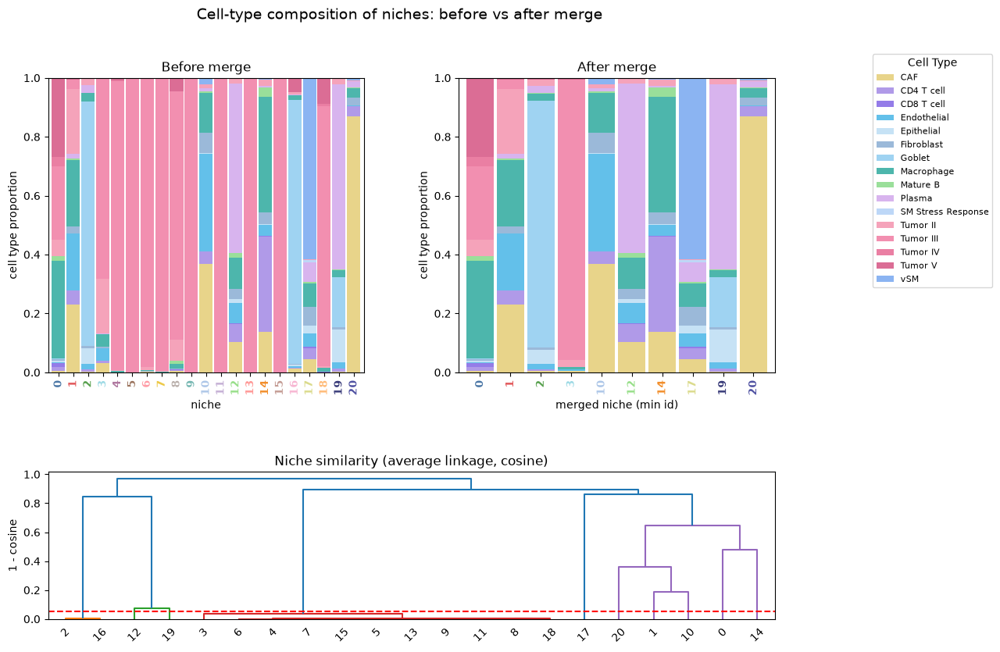

In [72]:
niche_palette = getattr(config, "umap_40")   # colors indexed by niche cluster id

# ---- Cell-type prediction (softmax temperature does not affect argmax, so it is comparable before/after) ----
cell_type = np.asarray(celltypes)[F.softmax(emb_all["cell"], dim=1).argmax(1).cpu().numpy()]

# ---- Composition table (before merge) ----
df_counts = pd.crosstab(np.asarray(clusters_id["niche"]), cell_type)

# ---- Hierarchical clustering + merge ----
comp = df_counts.div(df_counts.sum(1), axis=0)              # row-normalized composition
Z = linkage(comp.values, method="average", metric="cosine")

merge_thresh = 0.05
merged = fcluster(Z, t=merge_thresh, criterion="distance")
group_members = {}
for old, g in zip(comp.index, merged):
    group_members.setdefault(g, []).append(int(old))
old2new = {o: min(members) for members in group_members.values() for o in members}   # smallest id in each group becomes the new label

print(f"{len(comp)} niche clusters -> {len(set(old2new.values()))} merged")
for rep in sorted(set(old2new.values())):
    members = sorted(o for o, r in old2new.items() if r == rep)
    if len(members) > 1:
        print(f"  {members} -> {rep}")

niche_merged = np.array([old2new[l] for l in clusters_id["niche"]])
clusters_id["niche_merged"] = niche_merged

# ---- Composition table (after merge) ----
dfm = pd.crosstab(niche_merged, cell_type)

# ---- Convert to proportions (row-normalized, each bar stacks to 1) ----
comp_before = df_counts.div(df_counts.sum(1), axis=0)      # same as comp
comp_after  = dfm.div(dfm.sum(1), axis=0)

# ================= Layout: top row before/after merge, bottom row full-width dendrogram =================
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[2, 1], hspace=0.45, wspace=0.3)
ax_before = fig.add_subplot(gs[0, 0])
ax_after  = fig.add_subplot(gs[0, 1])
ax_dendro = fig.add_subplot(gs[1, :])

def stacked(ax, df, title, xlabel):
    """Stacked bar chart of cell-type proportions per niche; x tick labels colored by niche."""
    df.plot(kind="bar", stacked=True, ax=ax,
            color=[celltype_color[c] for c in df.columns], width=0.9, legend=False)
    for tick, nid in zip(ax.get_xticklabels(), df.index):
        tick.set_color(niche_palette[f"Cluster_{nid % 40}"]); tick.set_fontweight("bold")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("cell type proportion")
    ax.set_ylim(0, 1)

stacked(ax_before, comp_before, "Before merge", "niche")
stacked(ax_after,  comp_after,  "After merge",  "merged niche (min id)")

# Single legend on the right (the before-merge panel has the most complete set of types)
handles, labels = ax_before.get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(1.0, 0.92), loc="upper left",
           title="Cell Type", prop={"size": 8})

# Bottom row: dendrogram + merge threshold line
dendrogram(Z, labels=comp.index.tolist(), ax=ax_dendro)
ax_dendro.axhline(merge_thresh, ls="--", c="r")
ax_dendro.set_ylabel("1 - cosine")
ax_dendro.set_title("Niche similarity (average linkage, cosine)")

fig.suptitle("Cell-type composition of niches: before vs after merge", fontsize=14)
plt.show()

### 7.4 Niche spatial map before vs. after merge

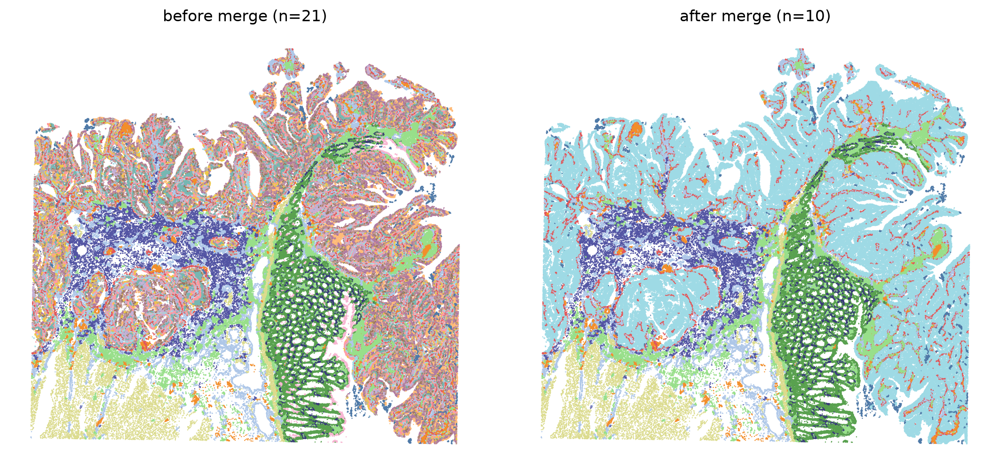

In [73]:
# Merged niche label for each cell (remapped with old2new from the merge step)
ids_merged = np.array([old2new[i] for i in ids])

fig, axes = plt.subplots(1, 2, figsize=(11, 5), dpi=200)

# Left: before merge
axes[0].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids], s=3, marker='.', linewidths=0)
axes[0].set_title(f"before merge (n={len(np.unique(ids))})")

# Right: after merge
axes[1].scatter(pos[:, 0], pos[:, 1],
                c=[umap_color[f"Cluster_{v % 40}"] for v in ids_merged], s=3, marker='.', linewidths=0)
axes[1].set_title(f"after merge (n={len(np.unique(ids_merged))})")

for a in axes:
    a.invert_yaxis(); a.set_aspect("equal"); a.axis("off")
plt.tight_layout()
plt.show()

## 8. ROI case studies

Regions of interest in full-resolution pixel coordinates, each given as `[x_min, y_min, x_max, y_max]`.

In [75]:
#ROIs = [[61350, 9950, 64150, 12550],
#        [44750, 3750, 46850, 5850],
#        [56850, 17750, 58950, 19850]]

ROIs = [[56250, 8250, 57350, 9350], 
        [47750, 9850, 49850, 11750],
        [61350, 9950, 64150, 12550],
        [55250, 13250, 57350, 15350]]

### 8.1 Cell types in the ROIs

In [76]:
fig, axes = plt.subplots(1, len(ROIs), figsize=(6*len(ROIs), 6), dpi=600)
for i, roi in enumerate(ROIs):
    x_min, y_min, x_max, y_max = roi
    utils.plot_roi_by_xy(
        axes[i], x_min, x_max, y_min, y_max,
        adata,
        S_s2c_updated,
        labels_all["cell"],
        celltype_color,
        fill_alpha=1,
        contour_lw=0.0
    )

plt.tight_layout()
plt.show()

### 8.2 Merged niches in the ROIs

In [ ]:
# --- Broadcast merged niche clusters to spots: spot -> cell -> niche (via the niche's center cell) ---
S = S_s2c_updated.coalesce()
s_rows, c_cols = S.indices()[0], S.indices()[1]
spot2cell = torch.full((S.size(0),), -1, dtype=torch.long, device=S.device)
spot2cell[s_rows] = c_cols.long()

cell_niche_cluster_id = torch.full((S.size(1),), -1, dtype=torch.long, device=S.device)
active_idx = torch.as_tensor(active_niche_indices, device=S.device).long()
cell_niche_cluster_id[active_idx] = torch.as_tensor(clusters_id["niche_merged"], device=S.device).long()

# Spots without a mapped cell / niche are labeled "Filtered"
cluster_at_spot = torch.where(spot2cell >= 0,
                              cell_niche_cluster_id[spot2cell],
                              torch.tensor(-1, dtype=torch.long, device=S.device)).cpu().numpy()
labels_niche_spot = ["Filtered" if v == -1 else f"Cluster_{v % 40}" for v in cluster_at_spot]

fig, axes = plt.subplots(1, len(ROIs), figsize=(6*len(ROIs), 6), dpi=600)
for i, roi in enumerate(ROIs):
    x_min, y_min, x_max, y_max = roi
    utils.plot_roi_by_xy(
        axes[i], x_min, x_max, y_min, y_max,
        adata,
        S_s2c_updated,
        labels_niche_spot,
        umap_color,
        fill_alpha=1,
        contour_lw=0.0
    )

plt.tight_layout()
plt.show()